# Peramalan Nilai Ekspor Pertanian Indonesia dengan LSTM

Notebook ini membangun dan mengevaluasi model **Long Short-Term Memory (LSTM)** untuk meramalkan nilai ekspor bulanan 14 komoditas pertanian Indonesia. Seluruh alur dikerjakan dari awal: eksplorasi data, praproses, pemodelan, pencarian parameter, peramalan, hingga visualisasi hasil.

---

## Ringkasan

| | |
|---|---|
| **Data** | Nilai Ekspor Bulanan Produk Pertanian menurut Komoditas, Badan Pusat Statistik (BPS), satuan juta US$ |
| **Cakupan** | 14 komoditas, Jan 2022 sampai Des 2025 (48 bulan per komoditas), ditambah Jan–Feb 2026 sebagai data pembanding |
| **Model** | Satu LSTM bersama untuk semua komoditas, peramalan rekursif multi-langkah |
| **Pertanyaan** | (1) Seberapa akurat LSTM meramalkan 6 bulan terakhir 2025? (2) Parameter apa yang memberi error terkecil? (3) Seberapa dekat ramalan Jan–Feb 2026 dengan angka aktualnya? |

> **Temuan utama**
>
> - Pencarian parameter menurunkan error uji dari NRMSE **0,232 menjadi 0,218** (look_back=3, units=64, lr=0,01, epochs=150).
> - LSTM **belum mengungguli pembanding sederhana** pada data sekecil ini: rata-rata historis masih sedikit lebih baik pada Jul–Des 2025 (0,208), dan ramalan "nilai terakhir" hampir sama baiknya pada Jan–Feb 2026 (0,148 vs 0,152).
> - Model bekerja baik pada komoditas yang **stabil** (Lada Hitam, Rumput Laut, Sarang Burung, Lain-lain) dan buruk pada yang **berubah level atau berlonjak** (Ikan Segar/Dingin, Kopi, Tembakau).

### Alur notebook

`Data mentah` → `Pembersihan` → `EDA` → `Pembagian kronologis` → `Normalisasi + sliding window` → `LSTM` → `Ramalan rekursif` → `Evaluasi vs pembanding` → `Visualisasi`

| Bagian | Isi |
|---|---|
| 1 | Persiapan lingkungan dan palet warna |
| 2 | Memuat dan membersihkan data |
| 3 | Eksplorasi data (EDA) |
| 4 | Praproses, arsitektur model, dan metrik |
| 5 | Ramalan Jul–Des 2025 dengan parameter awal |
| 6 | Pencarian parameter terbaik (grid search) |
| 7 | Ramalan Jan–Feb 2026 |
| 8 | Visualisasi hasil |
| 9 | Kesimpulan dan keterbatasan |

### Istilah yang dipakai

| Istilah | Arti |
|---|---|
| **LSTM** | Jaringan saraf rekuren dengan sel memori dan tiga gerbang (*forget*, *input*, *output*) yang mengatur informasi mana yang dipertahankan, sehingga cocok untuk data berurutan |
| **look_back** | Banyaknya bulan terakhir yang dilihat model untuk meramalkan bulan berikutnya |
| **units** | Jumlah neuron di dalam lapisan LSTM (kapasitas model) |
| **Peramalan rekursif** | Hasil ramalan bulan ke-*t* dipakai sebagai masukan untuk meramalkan bulan ke-*t+1* |
| **NRMSE** | RMSE dibagi rentang nilai data latih (maks − min); tanpa satuan sehingga bisa dibandingkan antar komoditas |
| **Pembanding (baseline)** | Metode sangat sederhana sebagai patokan: apakah model rumit benar-benar lebih baik? |
| **Seed** | Bilangan awal pengacak; beberapa seed dirata-ratakan agar hasil stabil |

---
## 1. Persiapan Lingkungan

Cell ini memuat pustaka dan menetapkan **satu palet warna yang konsisten** di seluruh grafik, supaya warna yang sama selalu bermakna sama (prinsip *similarity* pada Gestalt):

| Warna | Makna |
|---|---|
| Abu-abu | Data aktual (latar dan konteks) |
| Biru | Ramalan Jul–Des 2025 |
| Oranye | Ramalan Jan–Feb 2026 |
| Hijau | Periode validasi untuk memilih parameter |

Semua seed acak ditetapkan sehingga hasil dapat direproduksi.

In [1]:
import os, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")
from itertools import product
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

# Palet kategorikal tervalidasi (slot 1-3) dan token teks/permukaan
C_TEST, C_2026, C_VAL = "#2a78d6", "#eb6834", "#1baf7a"   # ramalan Jul-Des 2025 | Jan-Feb 2026 | validasi
C_ACT, C_ACT_LIGHT = "#6b6a65", "#c9c8c1"                   # data aktual | elemen non-sorot
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 100,
})
BLN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
SUMBER = "Sumber data: BPS, Nilai Ekspor Bulanan Produk Pertanian menurut Komoditas (juta US$)."
pd.set_option("display.width", 200, "display.max_columns", 30)
print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


---
## 2. Memuat dan Membersihkan Data

### 2.1 Data mentah
Sebelum mengubah apa pun, lihat bentuk asli file: ukuran, tipe kolom, dan nilai yang janggal. File berformat *wide*: satu baris mewakili satu komoditas pada satu tahun, dengan 12 kolom bulan. Format ini belum berupa deret waktu.

In [2]:
CANDIDATES = [Path("data/ekspor.xlsx"), Path("../../../Data/ekspor.xlsx")]
PATH = next(p for p in CANDIDATES if p.exists())
raw = pd.read_excel(PATH)

print("Ukuran:", raw.shape)
print("Jumlah sel bertanda '-':", int((raw.iloc[:, 2:] == "-").sum().sum()))
print("Tipe kolom:", raw.dtypes.value_counts().to_dict())
raw.iloc[[0, 1, 13, 14, 55, 56, 69]]

Ukuran: (70, 14)
Jumlah sel bertanda '-': 140
Tipe kolom: {dtype('O'): 11, dtype('float64'): 2, dtype('int64'): 1}


,Komoditas Ekspor Pertanian,Tahun,Januari,Februari,Maret,April,Mei,Juni,Juli,Agustus,September,Oktober,November,Desember
0,Sayur-sayuran,2022,2.8,2.6,3.9,2.8,3.2,3.3,9,13.4,17.9,21.6,11.5,6.8
1,Tembakau,2022,6.0,6.0,11.4,13.8,6.8,10.4,13.8,10.9,6.3,5.6,9.4,5.9
13,Lainnya,2022,88.2,76.7,91.5,86.9,75.6,91.3,98.5,88.1,85.3,104.8,95,87.9
14,Sayur-sayuran,2023,2.6,2.2,4.2,6.9,11.6,13.2,14.7,28,25.2,12.9,7.7,4.8
55,Lainnya,2025,132.6,142.2,127.1,123.4,140.5,100.7,122.7,122.1,117.1,122.2,113.6,130.7
56,Sayur-sayuran,2026,4.6,2.7,-,-,-,-,-,-,-,-,-,-
69,Lainnya,2026,120.0,116.8,-,-,-,-,-,-,-,-,-,-


> **Temuan**
>
> - File berisi 70 baris = 14 komoditas × 5 tahun (2022 sampai 2026) dan 12 kolom bulan.
> - Ada **140 sel `-`**, tepat 14 komoditas × 10 bulan yang belum terjadi pada 2026 (Mar–Des). Tanda `-` inilah yang membuat 11 kolom bulan terbaca sebagai teks (`object`) sehingga harus dikonversi.
> - Jan–Feb 2026 sudah berisi angka. Data ini disimpan terpisah dan baru dipakai di Bagian 7 sebagai pembanding ramalan.

### 2.2 Pembersihan dan restrukturisasi
Langkah yang dilakukan beserta alasannya:

1. **`-` diubah menjadi `NaN`** dengan `pd.to_numeric(errors="coerce")`, karena tanda tersebut berarti data belum dirilis.
2. **Bentuk *wide* diubah menjadi deret waktu** (`melt` lalu `pivot`) dengan indeks tanggal bulanan, karena LSTM membutuhkan urutan waktu.
3. **Nama komoditas dipersingkat** agar muat di judul grafik.
4. **Data dipisah dua**: `ts` (Jan 2022 sampai Des 2025) sebagai bahan utama, dan `aktual_2026` (Jan–Feb 2026) sebagai pembanding akhir yang tidak pernah dipakai untuk melatih maupun menyetel model.

In [3]:
NAMA = {
    "Sayur-sayuran": "Sayuran", "Tembakau": "Tembakau", "Jagung": "Jagung", "Kopi": "Kopi",
    "Tanaman Obat, Aromatik, dan Rempah-Rempah": "Tanaman Obat & Rempah",
    "Lada Hitam": "Lada Hitam", "Lada Putih": "Lada Putih", "Biji Kakao": "Biji Kakao",
    "Buah-buahan Tahunan": "Buah-buahan", "Sarang Burung": "Sarang Burung",
    "Hasil Hutan Bukan Kayu Lainnya": "HHBK Lainnya",
    "Ikan Segar/Dingin Hasil Tangkapan": "Ikan Segar/Dingin",
    "Rumput Laut dan Ganggang Lainnya": "Rumput Laut", "Lainnya": "Lain-lain",
}
raw.columns = ["komoditas", "tahun"] + list(range(1, 13))
long = raw.melt(id_vars=["komoditas", "tahun"], var_name="bulan", value_name="nilai")
long["nilai"] = pd.to_numeric(long["nilai"], errors="coerce")
long["komoditas"] = long["komoditas"].str.strip().map(NAMA)
assert long["komoditas"].notna().all(), "ada nama komoditas yang belum terpetakan"
long["tanggal"] = pd.to_datetime(dict(year=long["tahun"], month=long["bulan"], day=1))

wide = long.pivot(index="tanggal", columns="komoditas", values="nilai")[list(NAMA.values())].asfreq("MS")
ts = wide.loc[:"2025-12-01"].copy()                       # bahan utama: Jan 2022 - Des 2025
aktual_2026 = wide.loc["2026-01-01":"2026-02-01"].copy()  # pembanding akhir: Jan-Feb 2026

print(f"ts          : {ts.shape}  {ts.index[0]:%b %Y} - {ts.index[-1]:%b %Y}")
print(f"aktual_2026 : {aktual_2026.shape}  {aktual_2026.index[0]:%b %Y} - {aktual_2026.index[-1]:%b %Y}")
print("Missing di ts :", int(ts.isna().sum().sum()), "| nilai negatif:", int((ts < 0).sum().sum()),
      "| indeks bulanan lengkap:", ts.index.equals(pd.date_range(ts.index[0], ts.index[-1], freq="MS")))

ts          : (48, 14)  Jan 2022 - Dec 2025
aktual_2026 : (2, 14)  Jan 2026 - Feb 2026
Missing di ts : 0 | nilai negatif: 0 | indeks bulanan lengkap: True


> **Temuan**
>
> - `ts` berukuran **48 bulan × 14 komoditas**, `aktual_2026` berukuran 2 × 14.
> - Tidak ada nilai hilang, tidak ada nilai negatif, dan indeks bulanan lengkap tanpa bulan yang bolong, sehingga tidak perlu imputasi dan aman untuk dibuat *sliding window*.
> - Hanya 48 titik per deret. Ini batasan utama yang memengaruhi hampir seluruh keputusan pemodelan di bawah.

---
## 3. Eksplorasi Data (EDA)

### 3.1 Statistik deskriptif per komoditas
Tujuannya memahami **skala dan karakter** tiap deret sebelum memilih praproses. Kolom yang dihitung:

- `rata-rata`, `maks`: skala nilai, menentukan perlunya normalisasi.
- `CV` (std ÷ rata-rata): seberapa fluktuatif.
- `maks/median`: seberapa tajam lonjakan.
- `kontribusi_%`: peran komoditas terhadap total ekspor bulanan.
- Rerata per tahun: ada atau tidaknya pergeseran level (tren).

In [4]:
stat = pd.DataFrame({
    "rata-rata": ts.mean(), "std": ts.std(), "min": ts.min(), "maks": ts.max(),
    "CV": ts.std() / ts.mean(), "maks/median": ts.max() / ts.median(),
    "kontribusi_%": 100 * ts.mean() / ts.mean().sum(),
}).sort_values("rata-rata", ascending=False)
tahunan = ts.groupby(ts.index.year).mean().T.loc[stat.index]
tahunan.columns = [f"rerata {y}" for y in tahunan.columns]
display(stat.round(2).join(tahunan.round(1)))

,rata-rata,std,min,maks,CV,maks/median,kontribusi_%,rerata 2022,rerata 2023,rerata 2024,rerata 2025
komoditas,,,,,,,,,,,
Kopi,128.73,64.19,50.2,270.3,0.50,2.77,28.55,94.7,76.4,135.4,208.5
Lain-lain,110.69,19.28,75.6,154.8,0.17,1.35,24.55,89.1,105.0,124.0,124.6
Sarang Burung,46.87,10.37,20.6,73.9,0.22,1.62,10.40,49.2,52.8,46.0,39.5
Tanaman Obat & Rempah,44.56,10.89,27.1,67.5,0.24,1.67,9.88,50.5,38.8,35.5,53.5
Buah-buahan,41.25,21.69,10.2,93.0,0.53,2.72,9.15,25.5,27.8,48.4,63.3
Rumput Laut,22.15,9.09,12.4,46.5,0.41,2.54,4.91,33.4,23.7,16.1,15.4
Sayuran,14.68,12.37,2.2,51.5,0.84,4.46,3.26,8.2,11.2,18.1,21.2
Ikan Segar/Dingin,11.04,5.84,6.8,48.5,0.53,4.83,2.45,9.3,8.9,10.2,15.8
Lada Putih,8.25,3.60,3.3,17.8,0.44,2.52,1.83,6.6,5.3,10.3,10.8


> **Temuan**
>
> - **Skala sangat timpang**: rata-rata Kopi ±129 juta US$ vs HHBK Lainnya ±0,3, selisih ±400 kali. Karena itu tiap komoditas dinormalisasi sendiri dan error dibandingkan dengan NRMSE, bukan RMSE mentah.
> - **Fluktuasi** terbesar pada Lada Hitam (CV 1,05) dan Sayuran (0,84); lonjakan tertajam pada Lada Hitam (maks 8,7 kali median). Sebaliknya Lain-lain sangat stabil (CV 0,17).
> - **Level bergeser antar tahun**: Kopi 95 → 76 → 135 → 208, Buah-buahan 26 → 63, sedangkan Rumput Laut turun 33 → 15. Deret **tidak stasioner**, sehingga model yang hanya mengenal rentang nilai data latih akan sulit mengikuti kenaikan level yang berlanjut.
> - Lonjakan tajam (Jagung, Lada Hitam, Ikan) **tidak dibuang** sebagai *outlier*: itu kejadian ekspor nyata, dan bulan uji pun memuat lonjakan.

### 3.2 Siapa yang mendominasi ekspor?
Grafik batang terurut dengan **hanya tiga batang teratas yang diwarnai** (prinsip *figure–ground*: perhatian langsung tertuju pada yang penting, sisanya menjadi latar abu-abu). Nilai ditulis di ujung batang sehingga sumbu-x tidak perlu dibaca.

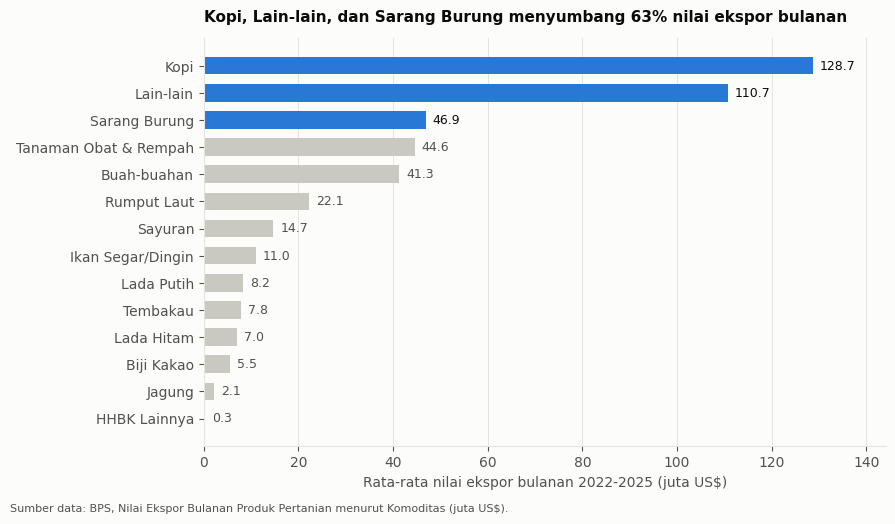

In [5]:
rata = ts.mean().sort_values()
top3 = list(rata.index[-3:][::-1])
share = 100 * rata[top3].sum() / rata.sum()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(rata.index, rata.values, color=[C_TEST if c in top3 else C_ACT_LIGHT for c in rata.index], height=0.65)
for y, v in enumerate(rata.values):
    ax.text(v + 1.5, y, f"{v:,.1f}", va="center", fontsize=9, color=INK if rata.index[y] in top3 else MUTED)
ax.set_xlim(0, rata.max() * 1.12)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Rata-rata nilai ekspor bulanan 2022-2025 (juta US$)")
ax.set_title(f"{top3[0]}, {top3[1]}, dan {top3[2]} menyumbang {share:.0f}% nilai ekspor bulanan", pad=12)
fig.text(0.01, 0.005, SUMBER, fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

> **Temuan**
>
> - Tiga komoditas (Kopi, Lain-lain, Sarang Burung) menyumbang ±63% nilai ekspor.
> - Kesalahan pada Kopi paling berdampak pada total nilai ekspor, tetapi NRMSE memperlakukan 14 komoditas **sama penting**. Karena itu hasil juga dibaca per komoditas, tidak hanya rata-ratanya.

### 3.3 Pola tiap komoditas sepanjang waktu
*Small multiples*: 14 panel dengan bentuk dan gaya identik (prinsip *similarity* dan *proximity*) sehingga pola mudah dibandingkan. **Sumbu-y dibuat bebas per panel** karena skala antar komoditas berbeda hingga ±500 kali; jika sumbu disamakan, sebagian besar deret akan tampak datar. Pita biru muda menandai **jendela uji Jul–Des 2025** yang nanti diramalkan.

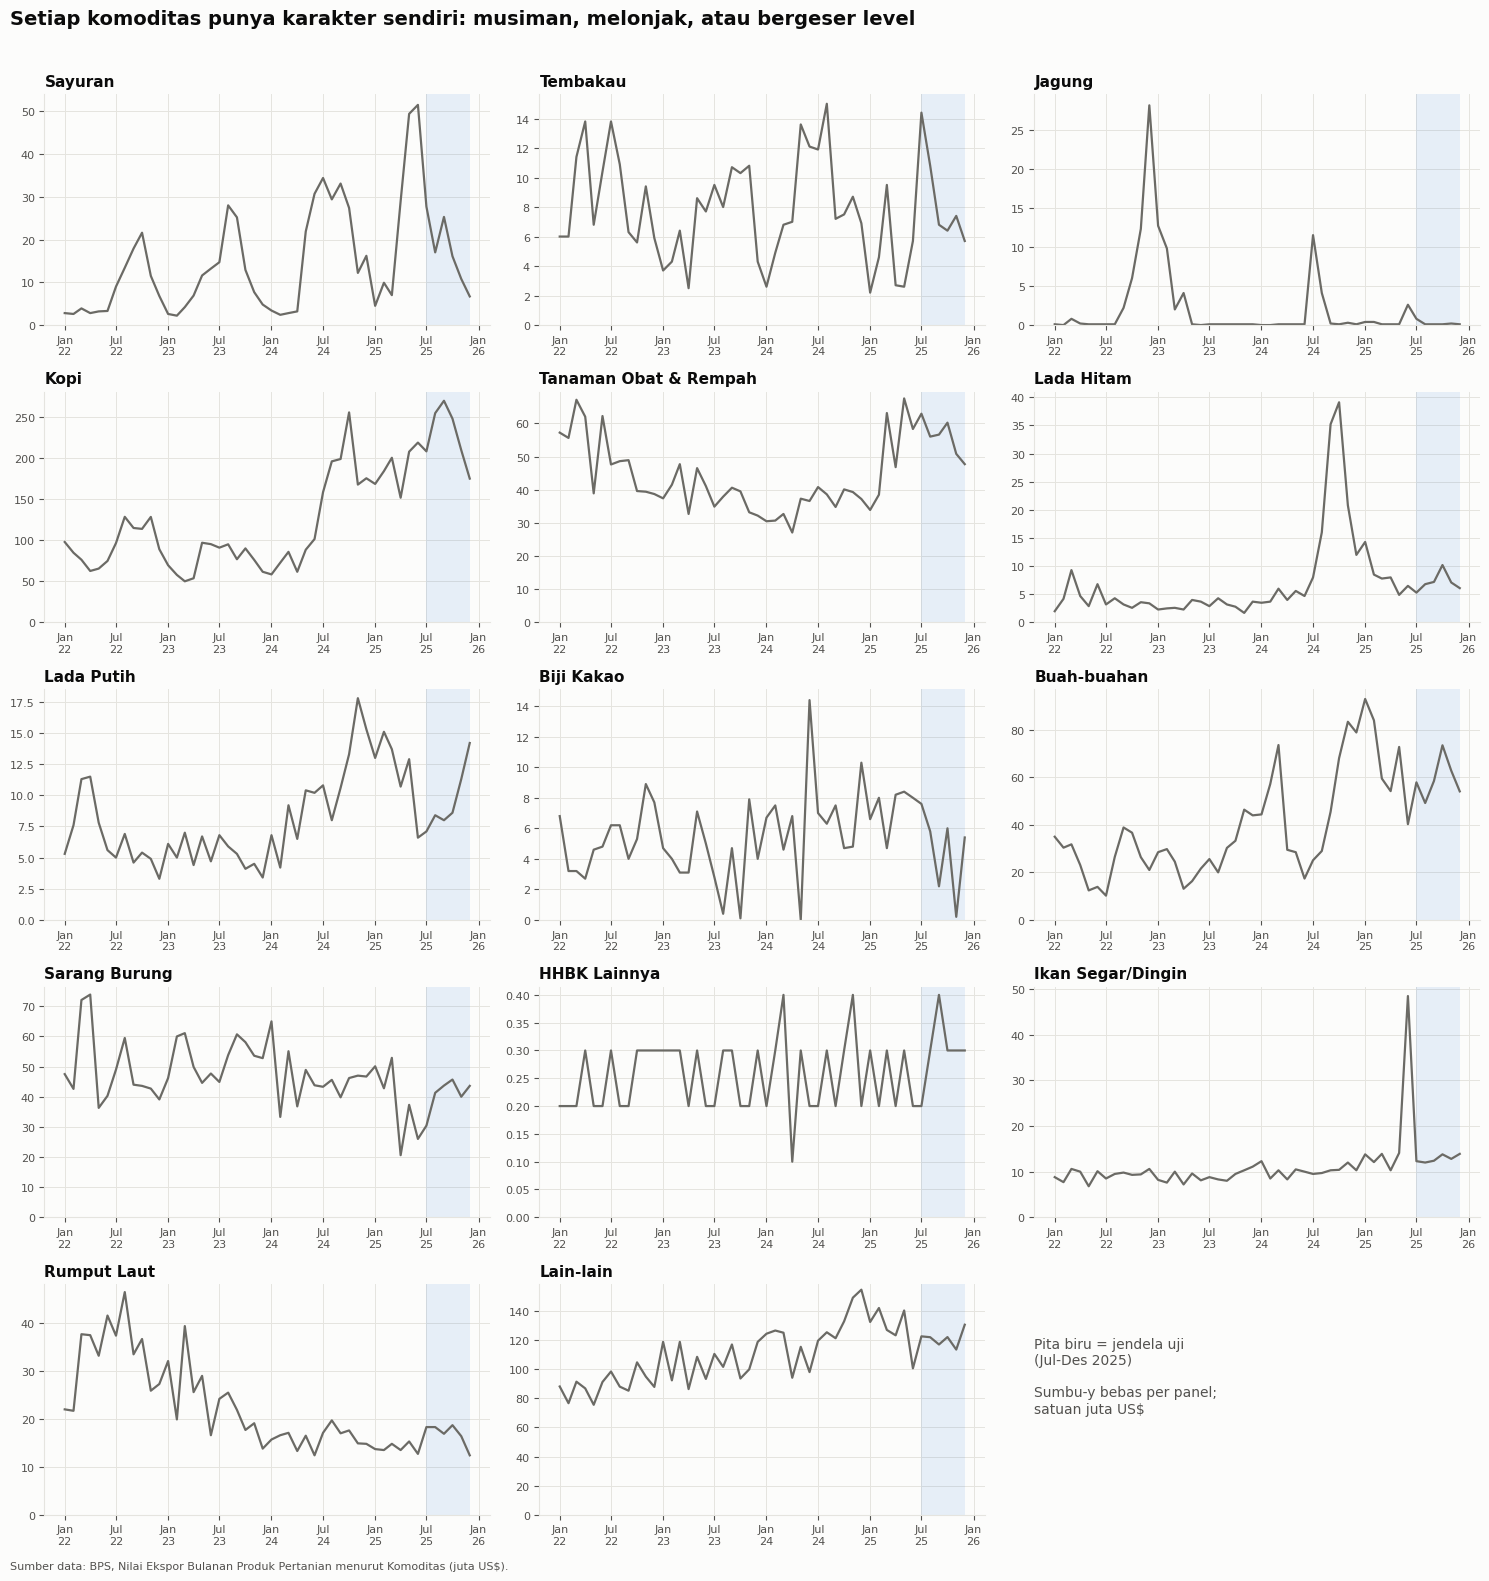

In [6]:
def fmt_bulan(x, pos=None):
    d = mdates.num2date(x)
    return f"{BLN[d.month - 1]}\n{d.year % 100:02d}"

def panel_grid(n_rows=5, n_cols=3, figsize=(15, 16)):
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    for ax in axes.flat:
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
        ax.xaxis.set_major_formatter(FuncFormatter(fmt_bulan))
        ax.tick_params(labelsize=8)
    return fig, axes

fig, axes = panel_grid()
for ax, c in zip(axes.flat, ts.columns):
    ax.axvspan(pd.Timestamp("2025-07-01"), pd.Timestamp("2025-12-01"), color=C_TEST, alpha=0.10, lw=0)
    ax.plot(ts.index, ts[c], color=C_ACT, lw=1.6)
    ax.set_title(c); ax.set_ylim(bottom=0)
ax = axes.flat[-1]; ax.axis("off")
ax.text(0, 0.6, "Pita biru = jendela uji\n(Jul-Des 2025)\n\nSumbu-y bebas per panel;\nsatuan juta US$", fontsize=10, color=MUTED, va="center")
fig.suptitle("Setiap komoditas punya karakter sendiri: musiman, melonjak, atau bergeser level", x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, SUMBER, fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.01, 1, 0.97)); plt.show()

> **Temuan**
>
> - **Bertren naik atau bergeser level**: Kopi (melonjak sejak 2024), Buah-buahan, Lain-lain, Sayuran. Berlawanan, Rumput Laut menurun.
> - **Musiman berulang**: Sayuran (puncak sekitar Agu–Okt tiap tahun), Tembakau, Buah-buahan.
> - **Lonjakan sesaat**: Jagung (Des 2022 dan Jul 2024), Lada Hitam (2024), Ikan Segar/Dingin (satu bulan Jun 2025 ±48 vs normal ±12).
> - **Berisik dan diskrit**: HHBK Lainnya (hanya bernilai 0,1–0,4) dan Biji Kakao.
> - Dua hal akan menyulitkan model: lonjakan Ikan **tepat sebelum** jendela uji, dan kenaikan Kopi ke level di luar rentang historis sebagian besar data latih.

### 3.4 Apakah ada pola musiman?
LSTM mempelajari pola dari urutan, jadi jika ada musim yang konsisten, `look_back` ≥ 12 bisa bermanfaat. Setiap komoditas di-*z-score* **per tahun** (agar pergeseran level antar tahun tidak mengotori pola musim), lalu dirata-ratakan per bulan kalender. Warna **divergen**: biru = di bawah rata-rata tahun itu, oranye = di atas, abu netral = sama dengan rata-rata. Baris diurutkan menurut bulan puncaknya sehingga pola musim membentuk *diagonal* yang mudah dikenali (prinsip *continuity*).

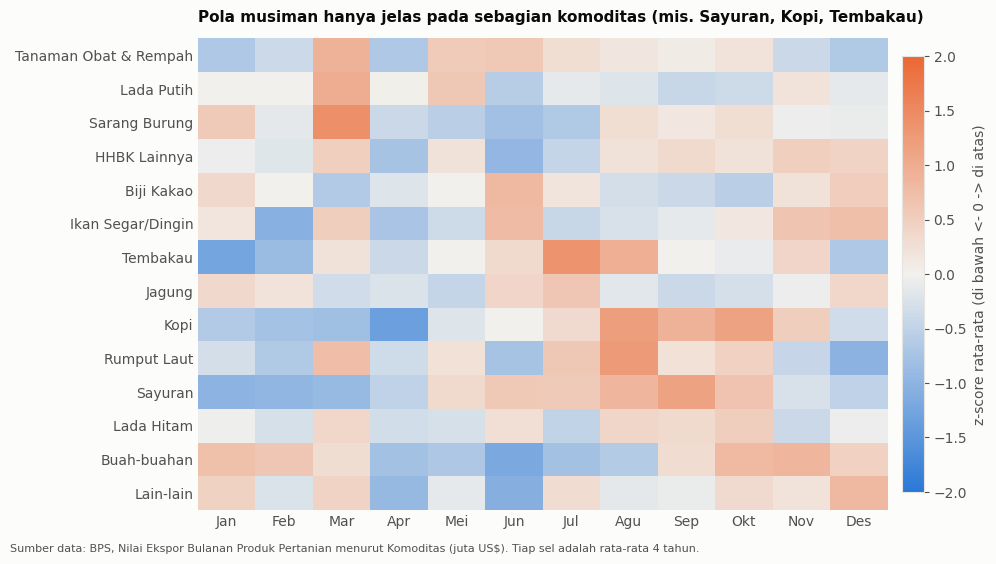

In [7]:
z = ts.groupby(ts.index.year).transform(lambda s: (s - s.mean()) / s.std())
musim = z.groupby(z.index.month).mean().T
musim = musim.iloc[np.argsort(musim.values.argmax(axis=1), kind="stable")]   # urut menurut bulan puncak

cmap = LinearSegmentedColormap.from_list("div", [C_TEST, "#f2f1ed", C_2026])
fig, ax = plt.subplots(figsize=(10, 5.6))
im = ax.imshow(musim.values, cmap=cmap, vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(12), BLN); ax.set_yticks(range(len(musim)), musim.index)
ax.grid(False); [s.set_visible(False) for s in ax.spines.values()]
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02); cb.set_label("z-score rata-rata (di bawah <- 0 -> di atas)")
ax.set_title("Pola musiman hanya jelas pada sebagian komoditas (mis. Sayuran, Kopi, Tembakau)", pad=12)
fig.text(0.01, 0.005, SUMBER + " Tiap sel adalah rata-rata 4 tahun.", fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.02, 1, 1)); plt.show()

> **Temuan**
>
> - Pola musiman jelas pada Sayuran dan Rumput Laut (naik di semester kedua, Agu–Okt), Tembakau (puncak Jul–Agu), dan Kopi (rendah Mar–Apr, tinggi Agu–Okt). Banyak komoditas lain tampak lemah atau acak.
> - Setiap sel hanya rata-rata dari **4 nilai** (4 tahun), sehingga polanya rapuh. `look_back` 12 (satu siklus musim) layak dicoba pada pencarian parameter, tetapi tidak boleh diasumsikan otomatis lebih baik.

---
## 4. Praproses, Arsitektur, dan Metrik

### 4.1 Pembagian data tanpa kebocoran informasi
Data deret waktu **tidak boleh diacak**: masa depan harus selalu berada setelah masa lalu. Pembagiannya:

| Himpunan | Periode | Fungsi |
|---|---|---|
| `sub_train` | Jan 2022 – Des 2024 | melatih model saat mencari parameter |
| `val` | Jan – Jun 2025 | memilih parameter terbaik |
| `train` | Jan 2022 – Jun 2025 | melatih model untuk evaluasi akhir |
| `test` | **Jul – Des 2025** | 6 bulan terakhir 2025 yang diramalkan dan dinilai |
| `ts` penuh | Jan 2022 – Des 2025 | melatih model untuk ramalan Jan–Feb 2026 |

Parameter dipilih pada `val`, **bukan** pada `test`. Memilih parameter memakai `test` membuat error yang dilaporkan terlalu optimistis karena data uji ikut "bocor" ke proses pemilihan. Diagram di bawah menunjukkan tiga skenario yang dijalankan.

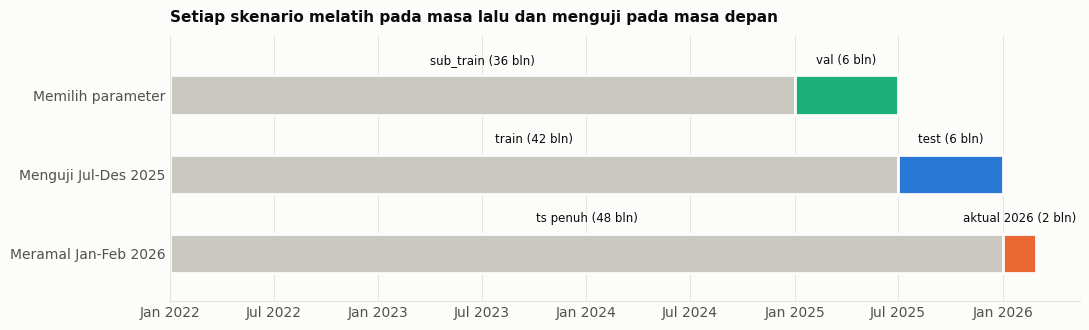

In [8]:
H = 6                                   # horizon uji: 6 bulan (Jul-Des 2025)
train, test = ts.iloc[:-H], ts.iloc[-H:]
sub_train, val = train.iloc[:-H], train.iloc[-H:]

def segmen(df):
    return mdates.date2num(df.index[0]), mdates.date2num(df.index[-1] + pd.offsets.MonthBegin(1)), len(df)

baris = [
    ("Memilih parameter",      [("sub_train", sub_train, C_ACT_LIGHT), ("val", val, C_VAL)]),
    ("Menguji Jul-Des 2025",   [("train", train, C_ACT_LIGHT), ("test", test, C_TEST)]),
    ("Meramal Jan-Feb 2026",   [("ts penuh", ts, C_ACT_LIGHT), ("aktual 2026", aktual_2026, C_2026)]),
]
fig, ax = plt.subplots(figsize=(11, 3.4))
for y, (nama, segs) in enumerate(baris):
    for lab, df, col in segs:
        a, b, n = segmen(df)
        ax.barh(y, b - a, left=a, height=0.5, color=col, edgecolor=SURFACE, linewidth=2)
        ax.text((a + b) / 2, y - 0.36, f"{lab} ({n} bln)", ha="center", va="bottom", fontsize=8.5, color=INK)
ax.set_yticks(range(len(baris)), [b[0] for b in baris]); ax.invert_yaxis(); ax.set_ylim(2.6, -0.75)
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: f"{BLN[mdates.num2date(x).month - 1]} {mdates.num2date(x).year}"))
ax.grid(axis="y", visible=False); ax.tick_params(length=0)
ax.set_title("Setiap skenario melatih pada masa lalu dan menguji pada masa depan", pad=10)
plt.tight_layout(); plt.show()

### 4.2 Normalisasi, sliding window, dan arsitektur
1. **Normalisasi `MinMaxScaler` per komoditas**, di-*fit* hanya pada data latih. Tanpa ini, Kopi (±150) akan mendominasi *loss* dibanding HHBK (±0,3).
2. **Sliding window**: model melihat `look_back` bulan terakhir lalu meramalkan bulan berikutnya, kemudian jendela digeser satu bulan, dan seterusnya. Bentuk masukan LSTM adalah `[sampel, time_steps, fitur]`.
3. **Satu LSTM bersama untuk 14 komoditas**: jendela dari semua komoditas digabung setelah dinormalisasi. Tiap deret hanya punya ±40 titik, jadi model per komoditas hanya punya puluhan sampel dan sangat mudah *overfit*. Penggabungan memberi ±14 kali lebih banyak sampel dan memungkinkan satu set parameter dicari untuk semua komoditas.
4. **Ramalan rekursif**: hasil ramalan bulan ke-*t* menjadi masukan bulan ke-*t+1*. Ini meniru situasi nyata (saat meramal Jul–Des, angkanya belum diketahui). Cara ini lebih sulit daripada meramal satu langkah memakai data aktual karena error menumpuk, tetapi lebih jujur.
5. **Ensemble seed**: tiap konfigurasi dilatih dengan beberapa seed lalu ramalannya dirata-ratakan. Rentang antar seed (minimum sampai maksimum) ikut disimpan sebagai gambaran ketidakpastian.

Arsitektur: `LSTM(units)` → `Dense(25, relu)` → `Dense(1)`, loss MSE, optimizer Adam. Ramalan negatif dipotong ke 0 karena nilai ekspor tidak mungkin negatif.

In [9]:
def make_windows(S, look_back):
    # S: array (T, n_komoditas) berskala [0,1] -> sampel gabungan dari semua komoditas
    X, y = [], []
    for j in range(S.shape[1]):
        for i in range(len(S) - look_back):
            X.append(S[i:i + look_back, j]); y.append(S[i + look_back, j])
    return np.array(X)[..., None], np.array(y)

def fit_forecast(train_df, horizon, look_back, units, lr, checkpoints, seed, batch_size=64):
    # Latih satu LSTM; simpan ramalan rekursif pada tiap epoch di `checkpoints` -> {epoch: DataFrame}
    tf.keras.backend.clear_session()
    scaler = MinMaxScaler().fit(train_df)
    S = scaler.transform(train_df)
    X, y = make_windows(S, look_back)
    tf.keras.utils.set_random_seed(seed)
    model = Sequential([Input((look_back, 1)), LSTM(units), Dense(25, activation="relu"), Dense(1)])
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="mean_squared_error")
    idx = pd.date_range(train_df.index[-1], periods=horizon + 1, freq="MS")[1:]
    hasil, selesai = {}, 0
    for ep in sorted(checkpoints):
        model.fit(X, y, epochs=ep - selesai, batch_size=batch_size, verbose=0)
        selesai = ep
        h = S[-look_back:].T[..., None]                       # (14 komoditas, look_back, 1)
        pred = []
        for _ in range(horizon):
            p = model(h, training=False).numpy()               # (14, 1)
            pred.append(p[:, 0])
            h = np.concatenate([h[:, 1:], p[:, None, :]], axis=1)
        hasil[ep] = pd.DataFrame(scaler.inverse_transform(np.array(pred)).astype("float64"),
                                 index=idx, columns=train_df.columns).clip(lower=0)
    return hasil

def ensemble(train_df, horizon, params, seeds):
    # Rata-rata ramalan beberapa seed, plus rentang minimum dan maksimum antar seed
    ep = params["epochs"]
    runs = [fit_forecast(train_df, horizon, params["look_back"], params["units"], params["lr"], [ep], s)[ep] for s in seeds]
    stack = np.stack([r.values for r in runs])
    buat = lambda a: pd.DataFrame(a, index=runs[0].index, columns=runs[0].columns)
    return buat(stack.mean(0)), buat(stack.min(0)), buat(stack.max(0))

# Peragaan bentuk data untuk look_back = 6
sc = MinMaxScaler().fit(train)
X_demo, y_demo = make_windows(sc.transform(train), 6)
print(f"train : {train.shape}  ->  X: {X_demo.shape} [sampel, time_steps, fitur],  y: {y_demo.shape}")
print(f"Nilai X dan y berada di rentang [{X_demo.min():.2f}, {X_demo.max():.2f}] (hasil MinMax)")

train : (42, 14)  ->  X: (504, 6, 1) [sampel, time_steps, fitur],  y: (504,)
Nilai X dan y berada di rentang [0.00, 1.00] (hasil MinMax)


> **Temuan**
>
> - Dari `train` (42 bulan) dengan `look_back=6` diperoleh **504 sampel** (14 komoditas × 36 jendela), semuanya di rentang [0, 1].
> - Jika model dibuat per komoditas, tiap model hanya mendapat 36 sampel. Penggabungan memberi ±14 kali lebih banyak.

### 4.3 Metrik evaluasi dan pembanding
- **RMSE** dan **MAE** (juta US$) mudah ditafsirkan per komoditas, tetapi **tidak bisa dibandingkan antar komoditas** karena skalanya berbeda.
- **NRMSE = RMSE ÷ (maks − min data latih)** tidak bersatuan sehingga bisa dirata-ratakan. Metrik inilah yang dipakai untuk memilih parameter. MAPE sengaja tidak dipakai karena nilai mendekati nol (Jagung, HHBK) membuatnya meledak.
- **Pembanding** menjawab "apakah LSTM lebih baik daripada cara yang sangat sederhana?":
  - *Naif*: mengulang nilai bulan terakhir.
  - *Musiman naif*: mengulang nilai bulan yang sama tahun lalu.
  - *Rata-rata*: rata-rata data latih.

Pada data sekecil ini, pembanding bisa sangat sulit dikalahkan, sehingga perbandingan ini penting untuk menilai model secara jujur.

In [10]:
def evaluate(actual, pred, train_df):
    err = pred.values - actual.values
    rmse = pd.Series(np.sqrt((err ** 2).mean(axis=0)), index=actual.columns)
    mae = pd.Series(np.abs(err).mean(axis=0), index=actual.columns)
    nrmse = rmse / (train_df.max() - train_df.min())
    return pd.DataFrame({"RMSE": rmse, "MAE": mae, "NRMSE": nrmse})

def baselines(train_df, horizon):
    idx = pd.date_range(train_df.index[-1], periods=horizon + 1, freq="MS")[1:]
    tile = lambda v: pd.DataFrame(np.tile(v, (horizon, 1)), index=idx, columns=train_df.columns)
    return {
        "Naif (nilai terakhir)": tile(train_df.iloc[-1].values),
        "Musiman naif (tahun lalu)": pd.DataFrame(train_df.iloc[-12:-12 + horizon].values, index=idx, columns=train_df.columns),
        "Rata-rata data latih": tile(train_df.mean().values),
    }

def ringkas(daftar, actual, train_df):
    # daftar: {nama model: ramalan}; hasil: ringkasan skor tiap model
    hasil = {n: evaluate(actual, p, train_df) for n, p in daftar.items()}
    return pd.DataFrame({
        "NRMSE rata-rata": {n: r["NRMSE"].mean() for n, r in hasil.items()},
        "NRMSE median": {n: r["NRMSE"].median() for n, r in hasil.items()},
        "MAE rata-rata (juta US$)": {n: r["MAE"].mean() for n, r in hasil.items()},
    }), hasil

---
## 5. Ramalan Jul–Des 2025 dengan Parameter Awal

Sebagai titik awal dipakai parameter yang wajar untuk data sekecil ini: `look_back=6`, `units=32`, `epochs=100`, Adam `lr=0.01`. Model dilatih pada `train` (Jan 2022 – Jun 2025) lalu meramalkan 6 bulan ke depan untuk **seluruh 14 komoditas**. Hasil 5 seed dirata-ratakan. Skor ini menjadi **pembanding** bagi hasil setelah pencarian parameter.

In [11]:
SEEDS = range(5)
DEFAULT = dict(look_back=6, units=32, lr=0.01, epochs=100)

t0 = time.time()
pred_default, _, _ = ensemble(train, H, DEFAULT, SEEDS)
print(f"Selesai dalam {time.time() - t0:.0f} detik")

pred_tbl = pred_default.copy(); pred_tbl.index = [BLN[d.month - 1] + " 2025" for d in pred_tbl.index]
print("Ramalan nilai ekspor Jul-Des 2025 (juta US$):")
display(pred_tbl.T.round(1))

ringk, ev = ringkas({"LSTM parameter awal": pred_default, **baselines(train, H)}, test, train)
print("Skor pada data uji (Jul-Des 2025):")
display(ringk.round(3))

Selesai dalam 46 detik
Ramalan nilai ekspor Jul-Des 2025 (juta US$):


,Jul 2025,Agu 2025,Sep 2025,Okt 2025,Nov 2025,Des 2025
komoditas,,,,,,
Sayuran,43.3,38.2,36.2,31.1,27.7,26.7
Tembakau,3.0,4.8,5.4,5.3,5.9,6.1
Jagung,3.4,4.9,5.6,6.3,6.7,6.7
Kopi,161.0,174.7,162.4,154.2,152.7,153.6
Tanaman Obat & Rempah,55.7,52.9,50.1,48.3,47.0,47.0
Lada Hitam,7.1,7.7,8.9,9.1,9.4,9.5
Lada Putih,10.6,9.3,9.2,9.9,9.7,9.9
Biji Kakao,7.9,7.6,7.4,7.4,7.3,7.2
Buah-buahan,51.8,49.8,47.9,49.5,50.3,49.8


Skor pada data uji (Jul-Des 2025):


,NRMSE rata-rata,NRMSE median,MAE rata-rata (juta US$)
LSTM parameter awal,0.232,0.184,10.907
Naif (nilai terakhir),0.302,0.268,12.595
Musiman naif (tahun lalu),0.230,0.228,9.348
Rata-rata data latih,0.208,0.189,13.597


> **Temuan**
>
> - LSTM parameter awal (NRMSE 0,232) lebih baik daripada *Naif* (0,302) dan hampir sama dengan *Musiman naif* (0,230), tetapi **belum mengalahkan Rata-rata data latih (0,208)**.
> - Ramalan cenderung **datar dan menuju rata-rata** (mis. Kopi ±155–175, HHBK ±0,2). Ini perilaku khas ramalan rekursif pada data sedikit: error tiap langkah menumpuk dan model "tertarik" ke level yang paling sering dilihatnya.

---
## 6. Mencari Parameter Terbaik (Grid Search)

| Parameter | Nilai yang dicoba | Mengapa penting |
|---|---|---|
| `look_back` | 3, 6, 12 | panjang memori; 12 = satu siklus musiman penuh |
| `units` | 16, 32, 64 | kapasitas LSTM; data kecil dan kapasitas besar rawan *overfit* |
| `lr` (Adam) | 0,01 dan 0,003 | kecepatan belajar |
| `epochs` | 25, 50, 100, 150 | lama latihan; terlalu lama berarti menghafal data latih |

**Cara kerja.** Tiap kombinasi dilatih pada `sub_train` (Jan 2022 – Des 2024) lalu diminta meramalkan `val` (Jan–Jun 2025) secara rekursif 6 bulan, persis meniru kondisi evaluasi sebenarnya. Skor adalah NRMSE rata-rata 14 komoditas, dirata-ratakan dari 3 seed. Untuk `epochs`, satu model dilatih bertahap dan dievaluasi pada epoch 25, 50, 100, dan 150, sehingga tidak perlu melatih ulang dari nol.

Seluruh grid memakan waktu **sekitar 20 menit**, sehingga hasilnya disimpan di `hasil_grid_search.csv`. Secara bawaan cell di bawah membaca file tersebut. Ubah `ULANG_GRID = True` untuk menjalankan ulang dari awal.

In [12]:
ULANG_GRID = False          # True = jalankan ulang seluruh grid (+-20 menit); False = baca hasil tersimpan
GRID = dict(look_back=[3, 6, 12], units=[16, 32, 64], lr=[0.01, 0.003], epochs=[25, 50, 100, 150])
GRID_SEEDS = [0, 1, 2]

if ULANG_GRID:
    rows, t0 = [], time.time()
    for lb, units, lr in product(GRID["look_back"], GRID["units"], GRID["lr"]):
        runs = [fit_forecast(sub_train, H, lb, units, lr, GRID["epochs"], s) for s in GRID_SEEDS]
        for ep in GRID["epochs"]:
            pred = sum(r[ep] for r in runs) / len(runs)
            rows.append(dict(look_back=lb, units=units, lr=lr, epochs=ep,
                             val_NRMSE=evaluate(val, pred, sub_train)["NRMSE"].mean()))
        print(f"look_back={lb:>2} units={units:>2} lr={lr:<5}  ({time.time() - t0:.0f} dtk)")
    grid = pd.DataFrame(rows).sort_values("val_NRMSE").reset_index(drop=True)
    grid.to_csv("hasil_grid_search.csv", index=False)
else:
    grid = pd.read_csv("hasil_grid_search.csv").sort_values("val_NRMSE").reset_index(drop=True)

BEST = grid.iloc[0][["look_back", "units", "lr", "epochs"]].to_dict()
BEST = {k: (float(v) if k == "lr" else int(v)) for k, v in BEST.items()}
print(f"{len(grid)} hasil dari {grid[['look_back', 'units', 'lr']].drop_duplicates().shape[0]} konfigurasi x {grid['epochs'].nunique()} titik epoch")
print("Parameter terbaik (NRMSE validasi terendah):", BEST)
print("\n10 hasil teratas:")
display(grid.head(10).round(4))

72 hasil dari 18 konfigurasi x 4 titik epoch
Parameter terbaik (NRMSE validasi terendah): {'look_back': 3, 'units': 64, 'lr': 0.01, 'epochs': 150}

10 hasil teratas:


,look_back,units,lr,epochs,val_NRMSE
0,3,64,0.010,150,0.4409
1,12,64,0.010,50,0.4433
2,3,64,0.010,100,0.4460
3,12,32,0.010,25,0.4480
4,12,32,0.003,100,0.4490
5,12,32,0.010,50,0.4494
6,12,64,0.010,100,0.4499
7,12,64,0.003,100,0.4500
8,12,16,0.003,25,0.4502
9,3,16,0.003,25,0.4506


> **Temuan**
>
> - Parameter terbaik menurut error validasi adalah **`look_back=3`, `units=64`, `lr=0.01`, `epochs=150`** dengan NRMSE validasi 0,441.
> - Sepuluh hasil teratas hanya berselisih **0,441–0,451**. Perbedaan antar konfigurasi kecil, mendekati variasi antar seed. Parameter "terbaik" di sini unggul tipis, bukan pemenang mutlak.
> - NRMSE validasi (±0,44) jauh lebih tinggi daripada NRMSE uji (±0,22) karena Jan–Jun 2025 memuat lonjakan Kopi dan Sayuran yang belum pernah dilihat model yang dilatih sampai Des 2024.
> - Parameter terbaik berada di **batas** grid `epochs` (150), jadi nilai di atas 150 belum diuji. Ini keterbatasan yang disengaja demi waktu komputasi.

### 6.1 Membaca hasil grid search
Panel kiri menunjukkan **kombinasi `look_back` × `units`** mana yang paling baik (nilai kotak = NRMSE validasi terendah di antara semua `lr` dan `epochs`; makin gelap makin kecil errornya). Panel kanan menunjukkan **pengaruh lama latihan** (`epochs`) sebagai rata-rata seluruh konfigurasi, untuk dua learning rate.

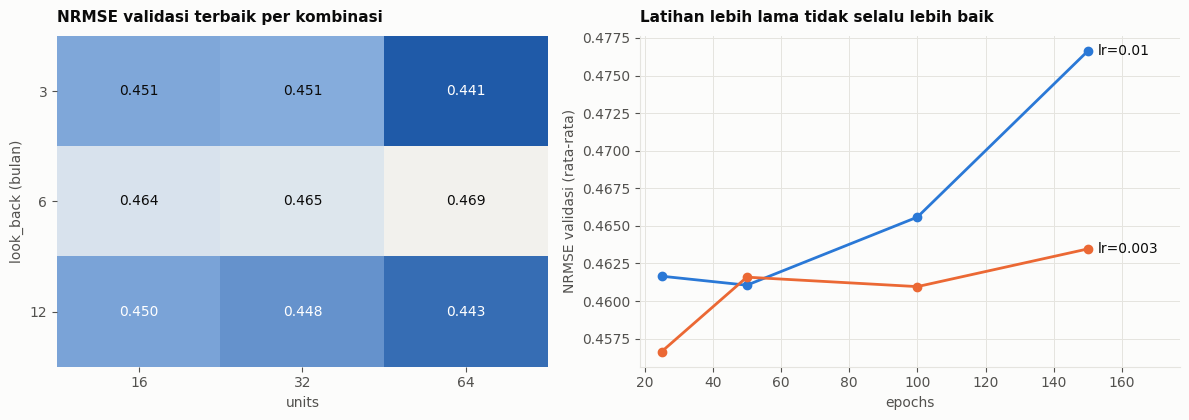

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 1.1]})

pv = grid.pivot_table(index="look_back", columns="units", values="val_NRMSE", aggfunc="min")
seq = LinearSegmentedColormap.from_list("seq", ["#1f5aa8", "#a9c9ef", "#f2f1ed"])
a1.imshow(pv.values, cmap=seq, aspect="auto")
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        a1.text(j, i, f"{pv.values[i, j]:.3f}", ha="center", va="center", fontsize=10,
                color="white" if pv.values[i, j] < np.nanmin(pv.values) + 0.35 * np.ptp(pv.values) else INK)
a1.set_xticks(range(pv.shape[1]), pv.columns); a1.set_yticks(range(pv.shape[0]), pv.index)
a1.set_xlabel("units"); a1.set_ylabel("look_back (bulan)"); a1.grid(False)
[s.set_visible(False) for s in a1.spines.values()]
a1.set_title("NRMSE validasi terbaik per kombinasi", pad=10)

for lr, col in zip(sorted(grid["lr"].unique(), reverse=True), (C_TEST, C_2026)):
    g = grid[grid["lr"] == lr].groupby("epochs")["val_NRMSE"].mean()
    a2.plot(g.index, g.values, color=col, lw=2, marker="o", ms=6)
    a2.text(g.index[-1] + 3, g.values[-1], f"lr={lr}", color=INK, va="center", fontsize=10)
a2.set_xlim(right=grid["epochs"].max() * 1.18)
a2.set_xlabel("epochs"); a2.set_ylabel("NRMSE validasi (rata-rata)")
a2.set_title("Latihan lebih lama tidak selalu lebih baik", pad=10)
plt.tight_layout(); plt.show()

> **Temuan**
>
> - **Kiri:** `units=64` unggul pada `look_back` 3 maupun 12, sedangkan `look_back=6` konsisten yang terburuk. Pola tidak monoton seperti ini mengisyaratkan selisihnya lebih berasal dari variasi acak daripada kecenderungan yang kuat.
> - **Kanan:** untuk `lr=0.01`, error rata-rata **naik** seiring `epochs` (model mulai menghafal data latih); `lr=0.003` lebih stabil.
> - Sumbu-y panel kanan sengaja tidak dimulai dari nol, sehingga seluruh rentangnya hanya ±0,02. Kemiringan tampak curam padahal selisih absolutnya kecil.

### 6.2 Menguji parameter terbaik pada data uji
Parameter `BEST` dipakai melatih ulang model pada `train` (Jan 2022 – Jun 2025, kini sudah termasuk `val`) lalu meramalkan **Jul–Des 2025**. Skor dibandingkan dengan parameter awal dan pembanding. Ini ukuran performa yang jujur karena `test` tidak dipakai sama sekali dalam pemilihan parameter.

In [14]:
pred_test, lo_test, hi_test = ensemble(train, H, BEST, SEEDS)
base_test = baselines(train, H)
ringk_test, ev_test = ringkas({"LSTM parameter awal": pred_default, "LSTM parameter terbaik": pred_test, **base_test}, test, train)
print("Parameter terbaik:", BEST)
display(ringk_test.round(3))

print("Error per komoditas, LSTM parameter terbaik (Jul-Des 2025):")
display(ev_test["LSTM parameter terbaik"].sort_values("NRMSE").round(3))

Parameter terbaik: {'look_back': 3, 'units': 64, 'lr': 0.01, 'epochs': 150}


,NRMSE rata-rata,NRMSE median,MAE rata-rata (juta US$)
LSTM parameter awal,0.232,0.184,10.907
LSTM parameter terbaik,0.218,0.180,10.108
Naif (nilai terakhir),0.302,0.268,12.595
Musiman naif (tahun lalu),0.230,0.228,9.348
Rata-rata data latih,0.208,0.189,13.597


Error per komoditas, LSTM parameter terbaik (Jul-Des 2025):


,RMSE,MAE,NRMSE
komoditas,,,
Lada Hitam,1.878,1.627,0.050
Rumput Laut,3.178,2.761,0.093
Sarang Burung,5.676,5.244,0.106
Lain-lain,11.284,10.111,0.142
Buah-buahan,12.521,9.975,0.151
Jagung,4.518,4.409,0.161
Lada Putih,2.342,1.834,0.162
Tanaman Obat & Rempah,8.011,6.360,0.198
Biji Kakao,3.932,3.080,0.273


> **Temuan**
>
> - Parameter terbaik menurunkan NRMSE dari **0,232 menjadi 0,218** dan MAE dari 10,9 menjadi 10,1. Perbaikannya nyata tetapi **sederhana** (±6%), sejalan dengan kecilnya selisih di grid search.
> - LSTM terbaik mengalahkan *Naif* (0,302) dan *Musiman naif* (0,230) pada NRMSE, tetapi **masih kalah dari Rata-rata data latih (0,208)**, dan pada MAE kalah dari *Musiman naif* (9,3). Pada data sekecil ini LSTM **belum terbukti lebih unggul** daripada cara sederhana.
> - Terbaik per komoditas: Lada Hitam (0,050), Rumput Laut (0,093), Sarang Burung (0,106). Terburuk: **Ikan Segar/Dingin (0,487)**, Kopi (0,329), Tembakau (0,309). Ikan terpengaruh lonjakan satu bulan (Jun 2025) yang diperlakukan seolah bertahan, sedangkan Kopi naik ke level di luar rentang latih.
> - Sebanyak 8 dari 14 komoditas punya NRMSE < 0,2.

---
## 7. Ramalan Januari dan Februari 2026

Dengan parameter terbaik, model dilatih ulang pada **seluruh data 2022–2025** (`ts`, 48 bulan) lalu meramalkan dua bulan berikutnya secara rekursif (Feb 2026 memakai ramalan Jan 2026 sebagai salah satu masukan).

File BPS ternyata sudah memuat angka **aktual Jan–Feb 2026**, sehingga ramalan dapat diperiksa terhadap kenyataan. Angka itu tidak pernah dipakai untuk melatih maupun menyetel model, jadi ini ujian ramalan yang sebenarnya.

In [15]:
H26 = 2
pred_2026, lo_26, hi_26 = ensemble(ts, H26, BEST, SEEDS)
base_2026 = baselines(ts, H26)
ringk_26, ev_26 = ringkas({"LSTM parameter terbaik": pred_2026, **base_2026}, aktual_2026, ts)

tab = pd.concat({"Ramalan": pred_2026.T, "Aktual": aktual_2026.T}, axis=1)
tab.columns = [f"{k} {BLN[d.month - 1]} 2026" for k, d in tab.columns]
tab = tab[[f"{k} {b} 2026" for b in ("Jan", "Feb") for k in ("Ramalan", "Aktual")]]
print("Ramalan vs aktual, Jan-Feb 2026 (juta US$):")
display(tab.round(1))
print("Skor pada Jan-Feb 2026:")
display(ringk_26.round(3))

Ramalan vs aktual, Jan-Feb 2026 (juta US$):


,Ramalan Jan 2026,Aktual Jan 2026,Ramalan Feb 2026,Aktual Feb 2026
komoditas,,,,
Sayuran,8.5,4.6,8.8,2.7
Tembakau,6.1,2.1,6.4,4.3
Jagung,1.0,0.2,1.4,0.1
Kopi,184.2,120.0,181.7,109.6
Tanaman Obat & Rempah,50.0,38.3,48.8,41.9
Lada Hitam,6.8,9.2,6.7,5.6
Lada Putih,12.1,13.6,11.5,12.1
Biji Kakao,4.4,2.2,6.1,5.7
Buah-buahan,57.4,45.5,55.9,38.4


Skor pada Jan-Feb 2026:


,NRMSE rata-rata,NRMSE median,MAE rata-rata (juta US$)
LSTM parameter terbaik,0.152,0.127,9.207
Naif (nilai terakhir),0.148,0.155,8.614
Musiman naif (tahun lalu),0.171,0.130,11.329
Rata-rata data latih,0.169,0.140,5.882


> **Temuan**
>
> - Ramalan sangat dekat pada komoditas yang stabil: **Lain-lain** (122,2 vs 120,0 dan 119,4 vs 116,8), **Lada Putih**, **HHBK Lainnya**, dan **Ikan Segar/Dingin** (14,2 vs 12,8 dan 14,3 vs 11,9).
> - Meleset jauh pada **Kopi** (ramalan ±182–184 vs aktual 120 dan 110): ekspor Kopi turun tajam di awal 2026, sedangkan model hanya meneruskan level tinggi 2025. Sarang Burung Feb 2026 juga turun hampir separuh (27,3) dan tidak terramalkan.
> - NRMSE LSTM (0,152) **praktis sama dengan Naif (0,148)** dan lebih baik daripada Musiman naif (0,171) dan Rata-rata (0,169). Pada MAE, Rata-rata justru terendah (5,9) karena Kopi 2026 kembali mendekati rata-rata historisnya.
> - Dengan hanya dua bulan pembanding, selisih ini belum cukup untuk menyatakan satu metode lebih unggul.

---
## 8. Visualisasi Hasil

### 8.1 Seluruh ramalan dalam satu pandangan
Prinsip yang diterapkan:

- **Data storytelling:** judul menyatakan temuan, bukan sekadar deskripsi. Warna hanya dipakai untuk membedakan *ramalan* dari *data* (abu-abu = latar, biru = ramalan Jul–Des 2025, oranye = ramalan Jan–Feb 2026), sehingga mata langsung menangkap bagian yang penting.
- **Gestalt:** *similarity* (14 panel berbentuk identik), *continuity* (garis ramalan disambung dari titik aktual terakhir sehingga terbaca sebagai kelanjutan deret), *common region* (pita biru muda menandai jendela uji), *proximity* (legenda ditaruh di panel kosong dalam kelompok panel, bukan di luar).
- **Ketidakpastian:** pita transparan di sekitar garis ramalan adalah rentang minimum sampai maksimum dari 5 seed.
- Lingkaran kosong abu-abu adalah angka **aktual** Jan–Feb 2026 sebagai kunci jawaban bagi ramalan oranye.

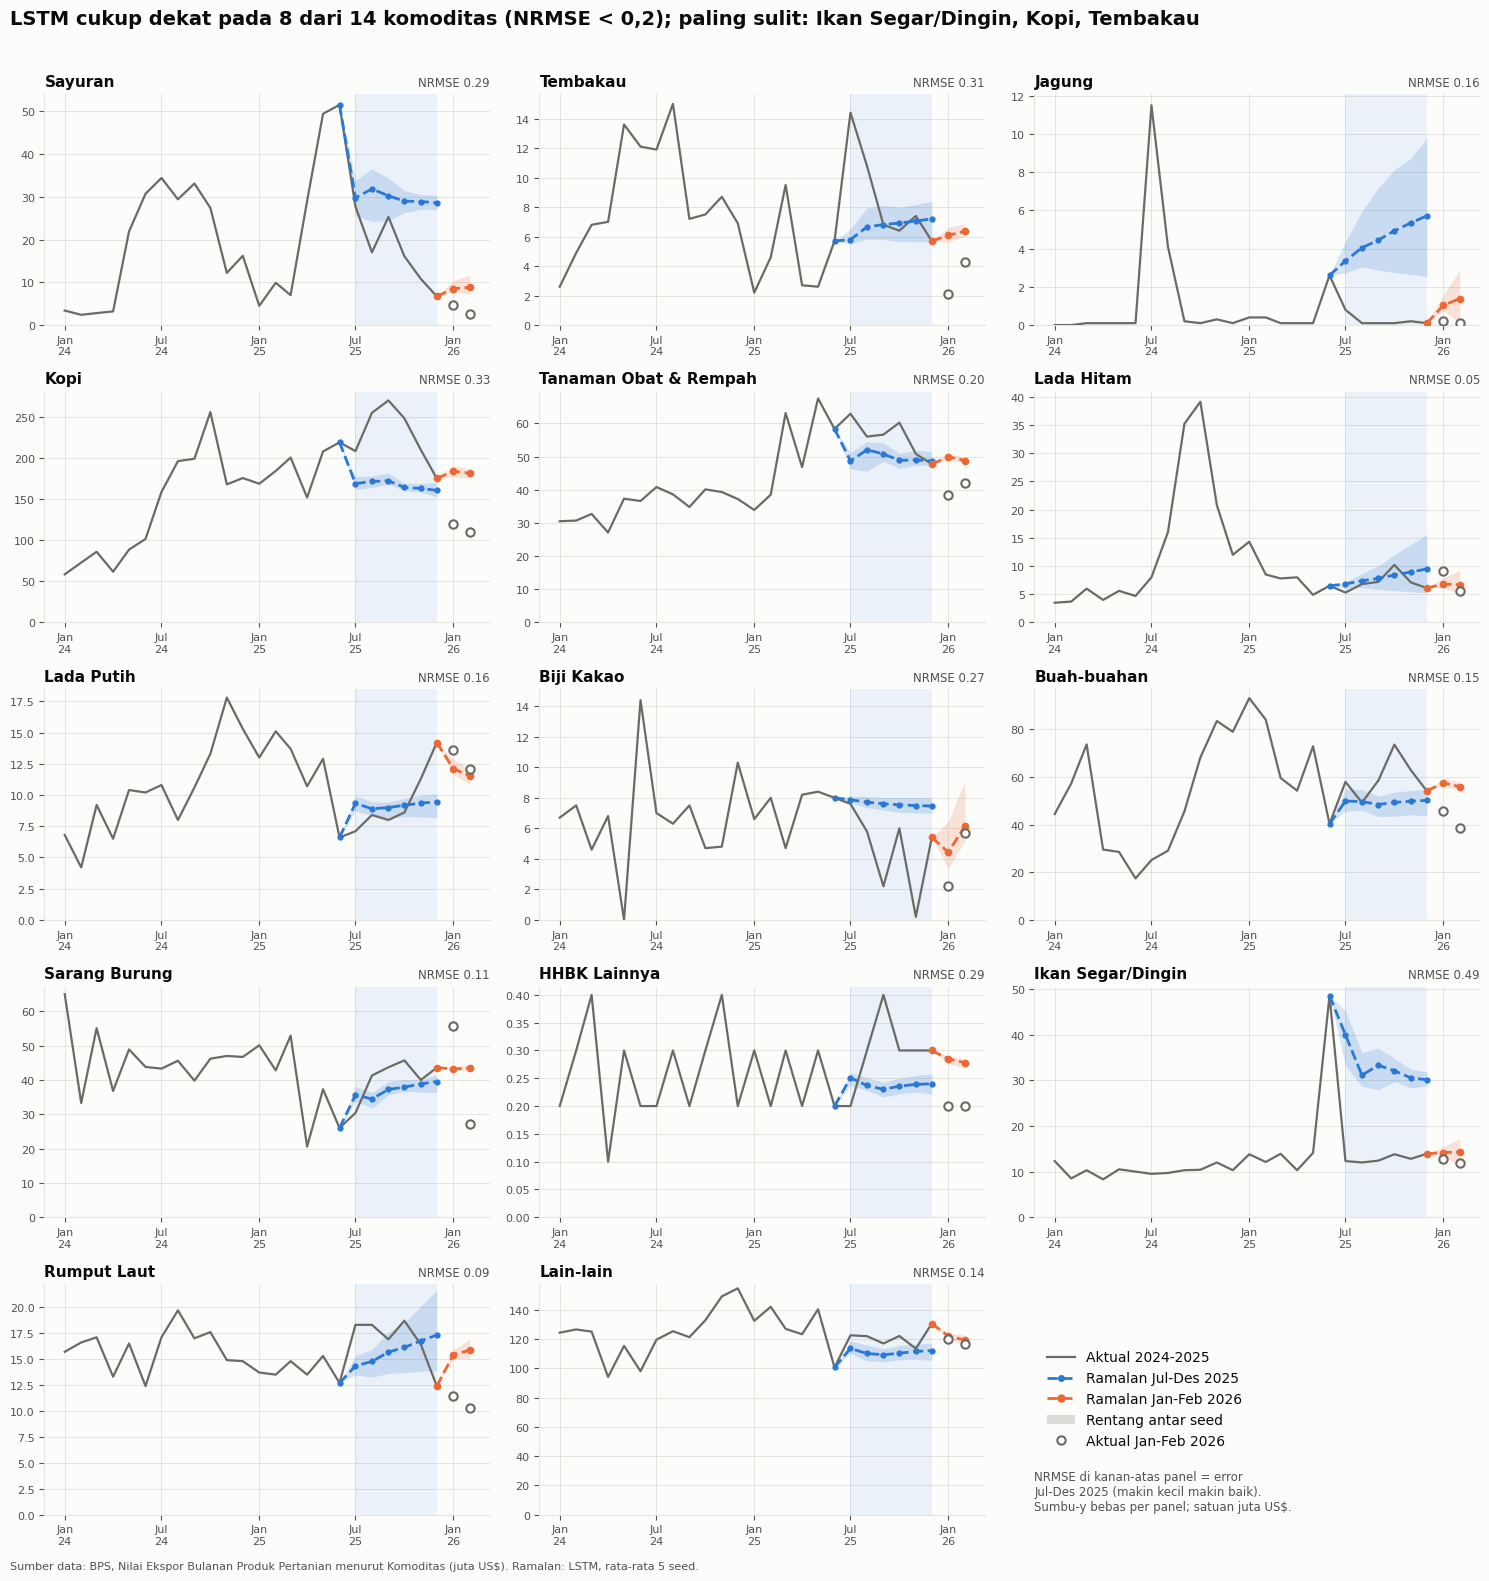

In [16]:
nr_test = ev_test["LSTM parameter terbaik"]["NRMSE"]
fig, axes = panel_grid()
j0, d0 = pd.Timestamp("2025-06-01"), pd.Timestamp("2025-12-01")
for ax, c in zip(axes.flat, ts.columns):
    ctx = ts[c].loc["2024-01-01":]
    ax.axvspan(pd.Timestamp("2025-07-01"), d0, color=C_TEST, alpha=0.08, lw=0)
    ax.plot(ctx.index, ctx.values, color=C_ACT, lw=1.6, zorder=3)
    for pred, lo, hi, ancr, col, ms in ((pred_test, lo_test, hi_test, j0, C_TEST, 3.5), (pred_2026, lo_26, hi_26, d0, C_2026, 4.5)):
        x = [ancr, *pred.index]
        ax.fill_between(x, [ts.loc[ancr, c], *lo[c]], [ts.loc[ancr, c], *hi[c]], color=col, alpha=0.18, lw=0, zorder=2)
        ax.plot(x, [ts.loc[ancr, c], *pred[c]], color=col, lw=2, ls="--", marker="o", ms=ms, zorder=4)
    ax.plot(aktual_2026.index, aktual_2026[c], ls="none", marker="o", ms=6, mfc=SURFACE, mec=C_ACT, mew=1.5, zorder=5)
    ax.set_title(c); ax.set_ylim(bottom=0)
    ax.set_title(f"NRMSE {nr_test[c]:.2f}", loc="right", fontsize=8.5, fontweight="normal", color=MUTED)
ax = axes.flat[-1]; ax.axis("off")
ax.legend(handles=[
    Line2D([], [], color=C_ACT, lw=1.6, label="Aktual 2024-2025"),
    Line2D([], [], color=C_TEST, lw=2, ls="--", marker="o", ms=4, label="Ramalan Jul-Des 2025"),
    Line2D([], [], color=C_2026, lw=2, ls="--", marker="o", ms=5, label="Ramalan Jan-Feb 2026"),
    Patch(facecolor=C_ACT_LIGHT, alpha=0.6, label="Rentang antar seed"),
    Line2D([], [], ls="none", marker="o", ms=6, mfc=SURFACE, mec=C_ACT, mew=1.5, label="Aktual Jan-Feb 2026"),
], loc="center left", frameon=False, fontsize=10)
ax.text(0, 0.02, "NRMSE di kanan-atas panel = error\nJul-Des 2025 (makin kecil makin baik).\nSumbu-y bebas per panel; satuan juta US$.", fontsize=8.5, color=MUTED, transform=ax.transAxes)
sulit = nr_test.nlargest(3).index.tolist()
fig.suptitle(f"LSTM cukup dekat pada {int((nr_test < 0.2).sum())} dari 14 komoditas (NRMSE < 0,2); paling sulit: {sulit[0]}, {sulit[1]}, {sulit[2]}",
             x=0.01, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.005, SUMBER + " Ramalan: LSTM, rata-rata 5 seed.", fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.01, 1, 0.97)); plt.show()

> **Temuan**
>
> - Ramalan biru mengikuti **level** data pada Lada Hitam, Rumput Laut, Sarang Burung, Lain-lain, dan Buah-buahan, tetapi **datar**: model belum menangkap naik-turun bulanan.
> - **Kopi**: kenyataan naik hingga ±270 sementara ramalan turun ke ±160–170. **Sayuran**: kenyataan jatuh lebih dalam (hingga ±10) daripada ramalan (±30). Perubahan level mendadak seperti ini tidak ada pada data latih.
> - **Ikan Segar/Dingin**: ramalan biru dimulai dari lonjakan Jun 2025 lalu turun pelan, padahal kenyataannya langsung kembali normal (±12) di Juli. Ini contoh jelas bagaimana satu *outlier* menjadi masukan yang menyesatkan pada ramalan rekursif. Pada Jan–Feb 2026 (oranye) lonjakan itu sudah keluar dari jendela masukan sehingga ramalannya jauh lebih dekat.
> - Pada Jan–Feb 2026, titik oranye berada dekat lingkaran kosong untuk komoditas stabil dan jauh untuk Kopi dan Sarang Burung.

### 8.2 Bagaimana LSTM dibandingkan metode sederhana?
Grafik batang menunjukkan **NRMSE rata-rata 14 komoditas** tiap metode (makin pendek makin baik). Hanya LSTM parameter terbaik yang diwarnai (*emphasis*: satu hal yang jadi pokok cerita, sisanya abu-abu), dan batang diurutkan sehingga peringkat terbaca langsung dari atas ke bawah.

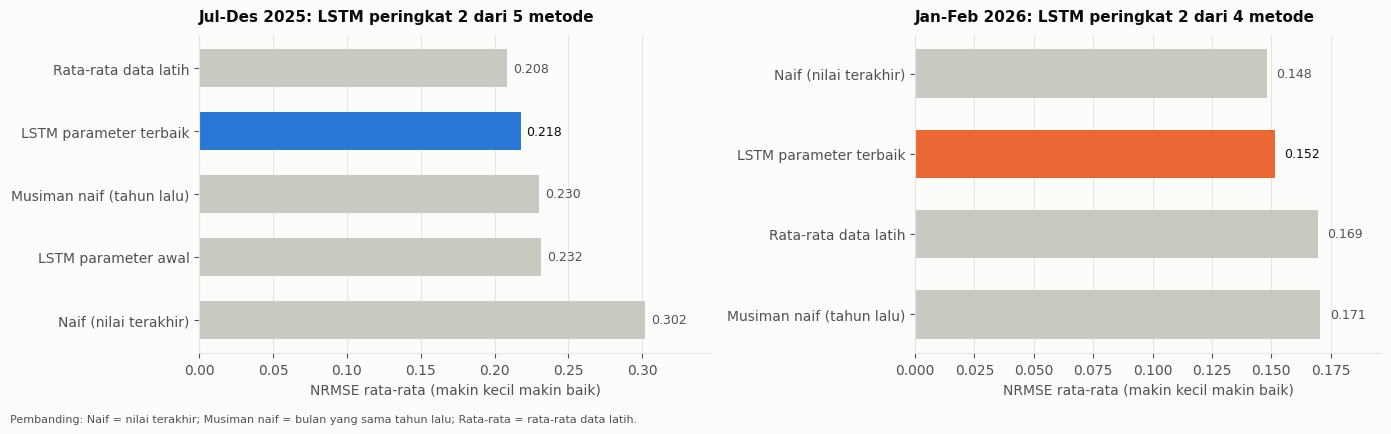

In [17]:
def bar_metode(ax, ringk, col, judul):
    s = ringk["NRMSE rata-rata"].sort_values(ascending=False)           # terbaik di atas
    ax.barh(s.index, s.values, height=0.6, color=[col if n == "LSTM parameter terbaik" else C_ACT_LIGHT for n in s.index])
    for y, (n, v) in enumerate(s.items()):
        ax.text(v + 0.004, y, f"{v:.3f}", va="center", fontsize=9, color=INK if n == "LSTM parameter terbaik" else MUTED)
    ax.set_xlim(0, s.max() * 1.15); ax.grid(axis="y", visible=False)
    ax.set_xlabel("NRMSE rata-rata (makin kecil makin baik)")
    rank = int(s.rank(ascending=True)["LSTM parameter terbaik"])
    ax.set_title(f"{judul}: LSTM peringkat {rank} dari {len(s)} metode", pad=10)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
bar_metode(a1, ringk_test, C_TEST, "Jul-Des 2025")
bar_metode(a2, ringk_26, C_2026, "Jan-Feb 2026")
fig.text(0.01, 0.005, "Pembanding: Naif = nilai terakhir; Musiman naif = bulan yang sama tahun lalu; Rata-rata = rata-rata data latih.", fontsize=8, color=MUTED)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

> **Temuan**
>
> - Pada Jul–Des 2025 LSTM terbaik peringkat kedua dari lima metode: lebih baik daripada Naif, Musiman naif, dan LSTM parameter awal, tetapi masih di belakang rata-rata historis.
> - Pada Jan–Feb 2026 LSTM peringkat kedua dari empat metode, hanya di belakang Naif. Keempat metode berada pada rentang sempit (0,148–0,171), dan dengan dua bulan uji urutannya tidak dapat dianggap meyakinkan.
> - Pesan praktis: untuk data sekecil ini, **model yang lebih kompleks tidak otomatis lebih akurat**, dan pembanding sederhana wajib disertakan.

### 8.3 Di komoditas mana LSTM berguna?
Grafik sebelumnya merangkum seluruh komoditas; grafik ini membedahnya. Sumbu-x adalah NRMSE (**makin ke kiri makin baik**). Titik biru atau oranye adalah LSTM, titik abu-abu adalah pembanding terbaik pada komoditas itu, dan garis penghubung menyatukan keduanya (prinsip *connection*). Garis berwarna berarti LSTM menang, garis abu-abu berarti kalah. Baris diurutkan menurut error LSTM sehingga komoditas tersulit berada di bawah.

Perlu dicatat bahwa pembanding di sini dipilih **setelah melihat hasil** (yang terbaik dari tiga pembanding pada tiap komoditas), sehingga ini tolok ukur yang ketat.

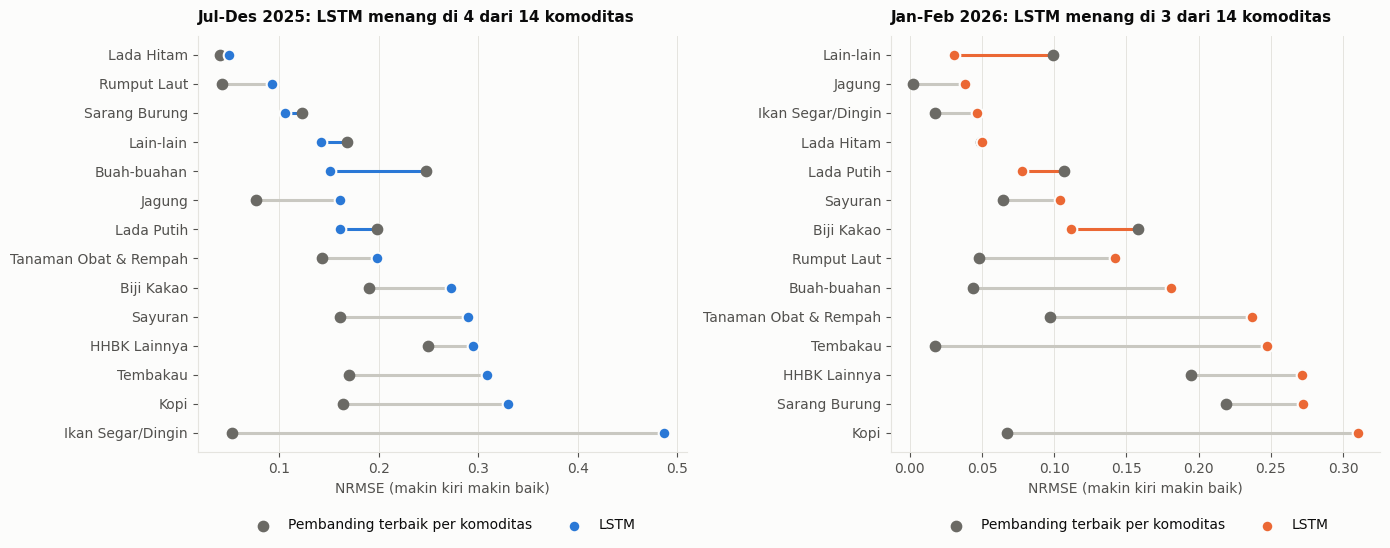

In [18]:
def dumbbell(ax, ev_lstm, ev_base_all, col, judul):
    lstm = ev_lstm["NRMSE"]
    best_base = pd.concat([e["NRMSE"] for e in ev_base_all], axis=1).min(axis=1)
    order = lstm.sort_values(ascending=False).index          # error terbesar di atas
    for y, c in enumerate(order):
        menang = lstm[c] < best_base[c]
        ax.plot([lstm[c], best_base[c]], [y, y], color=col if menang else C_ACT_LIGHT, lw=2.2, zorder=1)
    ax.scatter(best_base[order], range(len(order)), s=55, color=C_ACT, zorder=3, label="Pembanding terbaik per komoditas")
    ax.scatter(lstm[order], range(len(order)), s=70, color=col, zorder=4, edgecolor=SURFACE, linewidth=1.5, label="LSTM")
    ax.set_yticks(range(len(order)), order); ax.grid(axis="y", visible=False)
    ax.set_xlabel("NRMSE (makin kiri makin baik)")
    n_menang = int((lstm < best_base).sum())
    ax.set_title(f"{judul}: LSTM menang di {n_menang} dari {len(lstm)} komoditas", pad=10)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
    return n_menang

nama_base = list(base_test)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6))
m1 = dumbbell(a1, ev_test["LSTM parameter terbaik"], [ev_test[n] for n in nama_base], C_TEST, "Jul-Des 2025")
m2 = dumbbell(a2, ev_26["LSTM parameter terbaik"], [ev_26[n] for n in nama_base], C_2026, "Jan-Feb 2026")
plt.tight_layout(); plt.show()

> **Temuan**
>
> - LSTM unggul di **4 dari 14 komoditas** pada Jul–Des 2025 (Sarang Burung, Lain-lain, Buah-buahan, Lada Putih) dan 3 dari 14 pada Jan–Feb 2026 (Lain-lain, Lada Putih, Biji Kakao), padahal lawannya adalah pembanding terbaik yang dipilih setelah melihat hasil.
> - Lain-lain dan Lada Putih menang di kedua periode, sedangkan Kopi, Tembakau, dan HHBK konsisten lebih baik diramalkan oleh pembanding.
> - LSTM bersama berguna untuk deret yang **stabil atau berlevel tetap**, dan kurang berguna untuk deret yang **berubah level atau berlonjak**.

---
## 9. Kesimpulan

| Pertanyaan | Jawaban |
|---|---|
| Seberapa akurat ramalan 6 bulan terakhir 2025? | NRMSE rata-rata **0,232** dengan parameter awal, **0,218** dengan parameter terbaik. Delapan dari 14 komoditas punya NRMSE < 0,2. |
| Parameter mana yang memberi error terkecil? | `look_back=3`, `units=64`, `lr=0.01`, `epochs=150` (dipilih pada data validasi, bukan data uji). |
| Seberapa dekat ramalan Jan–Feb 2026? | NRMSE **0,152** terhadap angka aktual: dekat untuk komoditas stabil, meleset jauh untuk Kopi dan Sarang Burung. |

### Temuan utama
1. **Pencarian parameter memperbaiki hasil dalam skala kecil tetapi konsisten pada data uji** (0,232 → 0,218). Selisih antar konfigurasi di grid search sangat kecil, sehingga parameter terbaik tidak boleh dianggap pemenang telak.
2. **LSTM belum terbukti mengungguli pembanding sederhana** pada data ini: kalah dari rata-rata historis pada Jul–Des 2025 dan seri dengan ramalan Naif pada Jan–Feb 2026. Penyebab utamanya adalah hanya 48 titik per komoditas, deret yang tidak stasioner (Kopi dan Buah-buahan bergeser level), dan lonjakan sesaat (Ikan dan Jagung).
3. **Model bekerja baik untuk komoditas yang stabil** (Lada Hitam, Rumput Laut, Sarang Burung, Lain-lain, Lada Putih) dan **buruk untuk yang berubah level atau berlonjak** (Ikan Segar/Dingin, Kopi, Tembakau, Sayuran).

### Keterbatasan
- Ramalan rekursif membuat error menumpuk dan hasilnya cenderung mendatar.
- Parameter dipilih pada satu jendela validasi 6 bulan; jendela lain bisa memberi pemenang berbeda.
- Hanya 2 bulan data aktual 2026, sehingga evaluasi Jan–Feb 2026 tidak stabil secara statistik.
- Nilai `epochs` terbaik berada di batas grid (150).

### Langkah lanjutan yang masuk akal
- Memodelkan **selisih atau pertumbuhan** alih-alih level agar tren dapat diikuti.
- Menambahkan **fitur bulan** (musiman) sebagai masukan tambahan.
- Membuat model terpisah untuk kelompok komoditas yang berkarakter serupa.
- Memakai **validasi berjalan** (*rolling-origin*) pada beberapa jendela agar pemilihan parameter lebih kokoh.